# Install Requirements

In [1]:
!pip install numpy pandas scikit-learn torch

In [4]:
!pip install torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 38.9 MB/s eta 0:00:00


# Start Coding for CMaps dataset

In [5]:
# graph_phm_pipeline.py
# Ref: https://www.kaggle.com/code/wassimderbel/nasa-predictive-maintenance-rul
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, r2_score, mean_absolute_error
import torch
import torch.nn as nn
import torch.optim as optim
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
import sklearn
import warnings
import torch.optim as optimizer
from torch.utils.data import Dataset
from torch_geometric.loader import DataLoader  # Use PyG DataLoader
from torch_geometric.data import Data
from torch_geometric.nn import GATConv

np.random.seed(34)

## Connect to Drive

In [6]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Replace 'your_file.csv' with the actual path to your CSV file in Google Drive

index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['sensor_{}'.format(i+1) for i in range(0,21)]
col_names = index_names + setting_names + sensor_names

base_path = '/content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/'


dftrain = pd.read_csv(base_path + 'train_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
dfvalid = pd.read_csv(base_path + 'test_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
y_valid = pd.read_csv(base_path + 'RUL_FD001.txt',sep='\s+',header=None,index_col=False,names=['RUL'])

dfvalid.shape


<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-669062334.py:11: SyntaxWarning: invalid escape sequence '\s'
  dftrain = pd.read_csv(base_path + 'train_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
/tmp/ipython-input-669062334.py:12: SyntaxWarning: invalid escape sequence '\s'
  dfvalid = pd.read_csv(base_path + 'test_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
/tmp/ipython-input-669062334.py:13: SyntaxWarning: invalid escape sequence '\s'
  y_valid = pd.read_csv(base_path + 'RUL_FD001.txt',sep='\s+',header=None,index_col=False,names=['RUL'])


(13096, 26)

In [13]:
display(dfvalid)

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,520.69,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,521.05,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,521.18,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,521.33,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699


In [11]:
dftrain


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [14]:
y_valid

,RUL
0,112
1,98
2,69
3,82
4,91
...,...
95,137
96,82
97,59
98,117


In [9]:
train = dftrain.copy()
valid = dfvalid.copy()


In [10]:
display(train)

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [12]:
print('Shape of the train dataset : ',train.shape)
print('Shape of the validation dataset : ',valid.shape)
print('Percentage of the validation dataset : ',len(valid)/(len(valid)+len(train)))

Shape of the train dataset :  (20631, 26)
Shape of the validation dataset :  (13096, 26)
Percentage of the validation dataset :  0.3882942449669404


In [ ]:
train.loc[:,['unit_number','time_cycles']].describe()


,unit_number,time_cycles
count,20631.000000,20631.000000
mean,51.506568,108.807862
std,29.227633,68.880990
min,1.000000,1.000000
25%,26.000000,52.000000
50%,52.000000,104.000000
75%,77.000000,156.000000
max,100.000000,362.000000


In [ ]:
train.loc[:,'sensor_1':].describe().transpose()


,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,4.660829e-13,1.3000,1.3000,1.3000,1.3000,1.3000


## Maximum time cycle of each unit

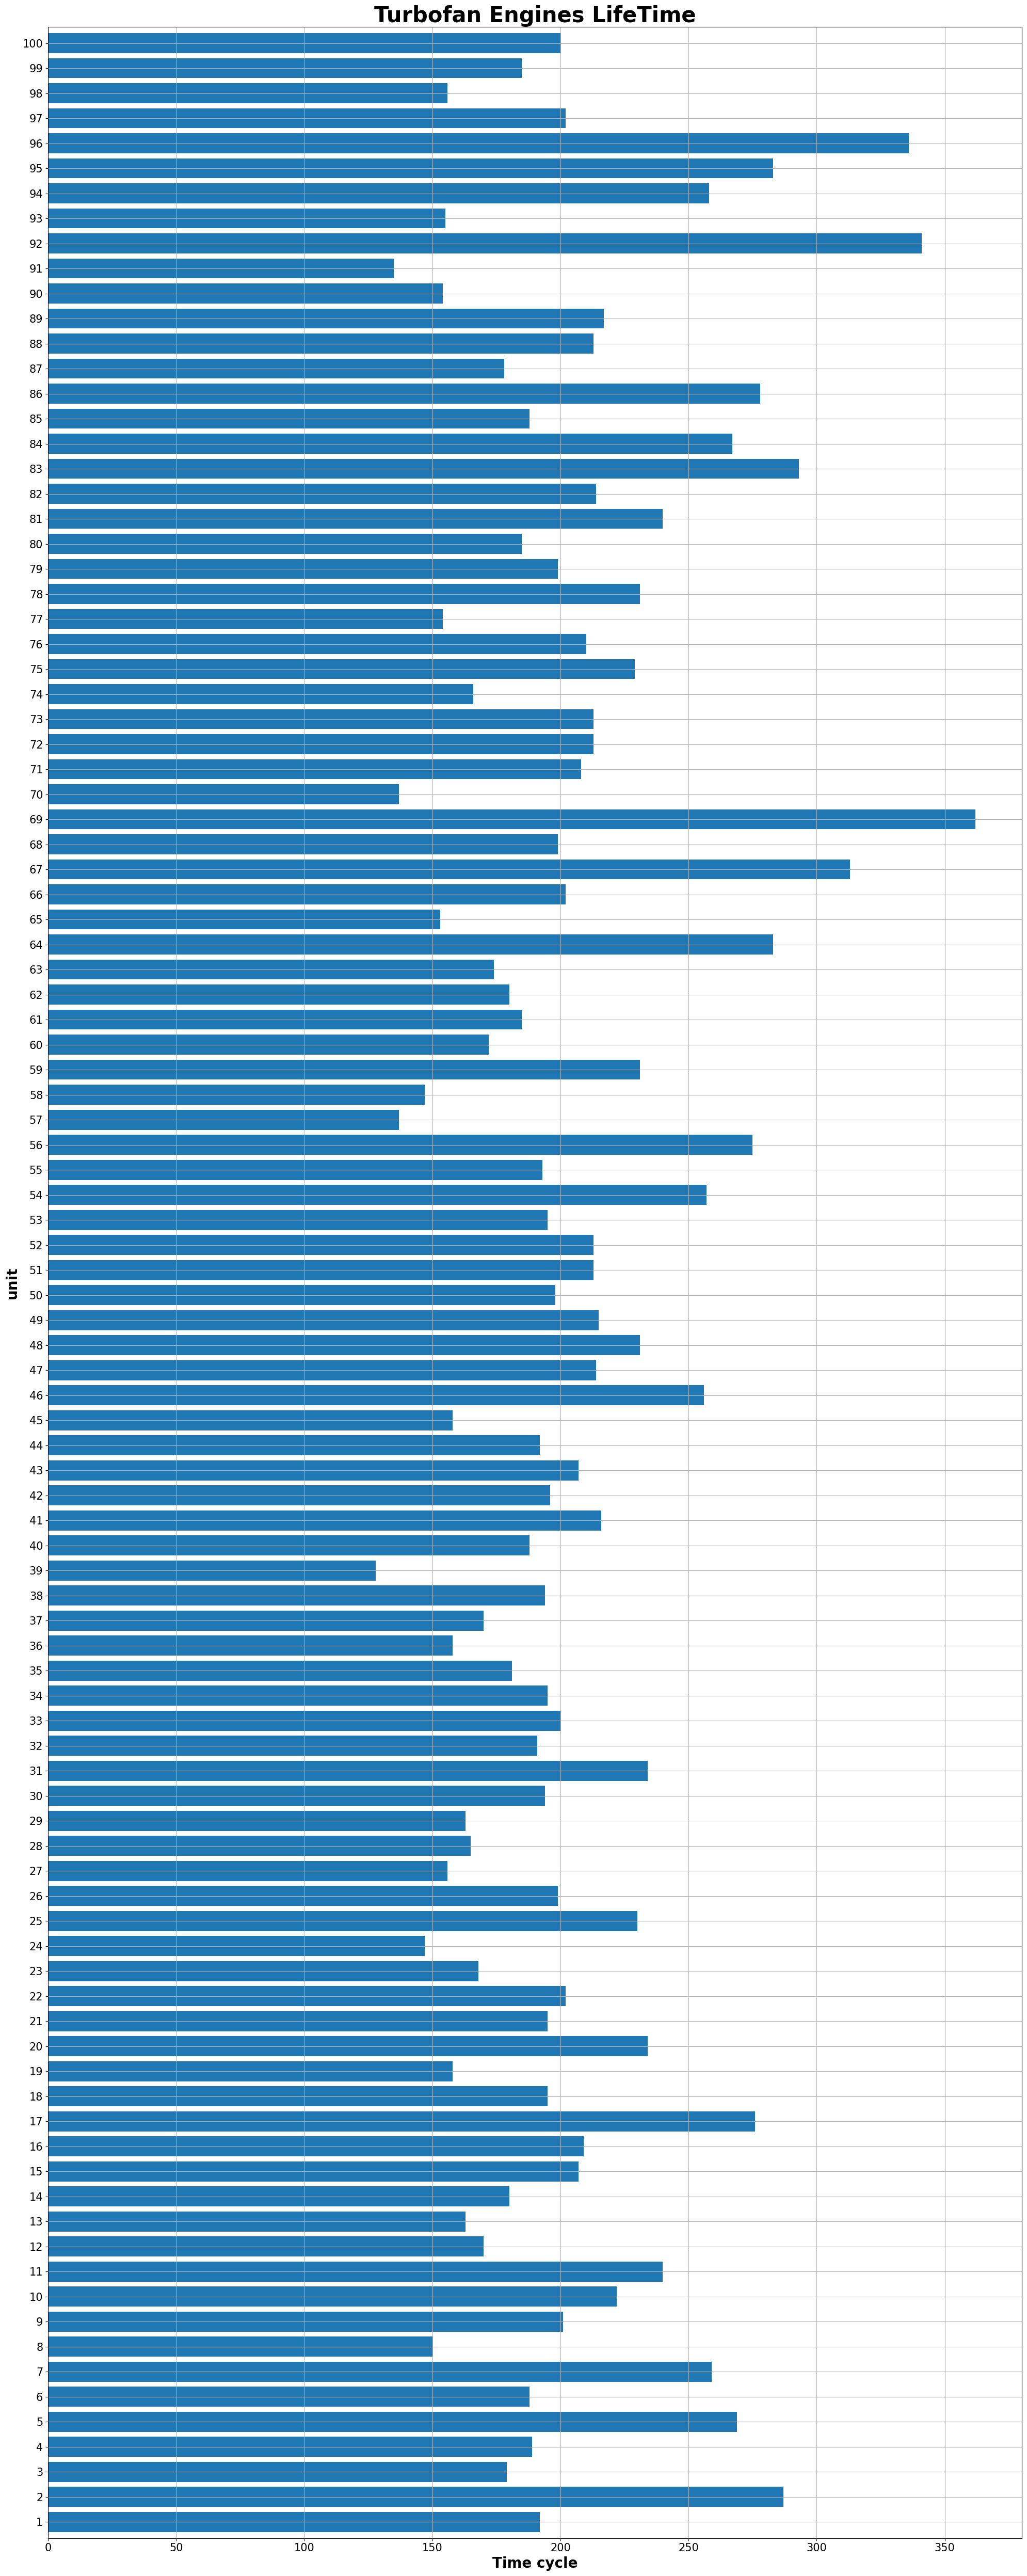

In [ ]:
max_time_cycles=train[index_names].groupby('unit_number').max()
plt.figure(figsize=(20,50))
ax=max_time_cycles['time_cycles'].plot(kind='barh',width=0.8, stacked=True,align='center')
plt.title('Turbofan Engines LifeTime',fontweight='bold',size=30)
plt.xlabel('Time cycle',fontweight='bold',size=20)
plt.xticks(size=15)
plt.ylabel('unit',fontweight='bold',size=20)
plt.yticks(size=15)
plt.grid(True)
plt.tight_layout()
plt.show()

Text(0.5, 9.444444444444459, 'max time cycle')

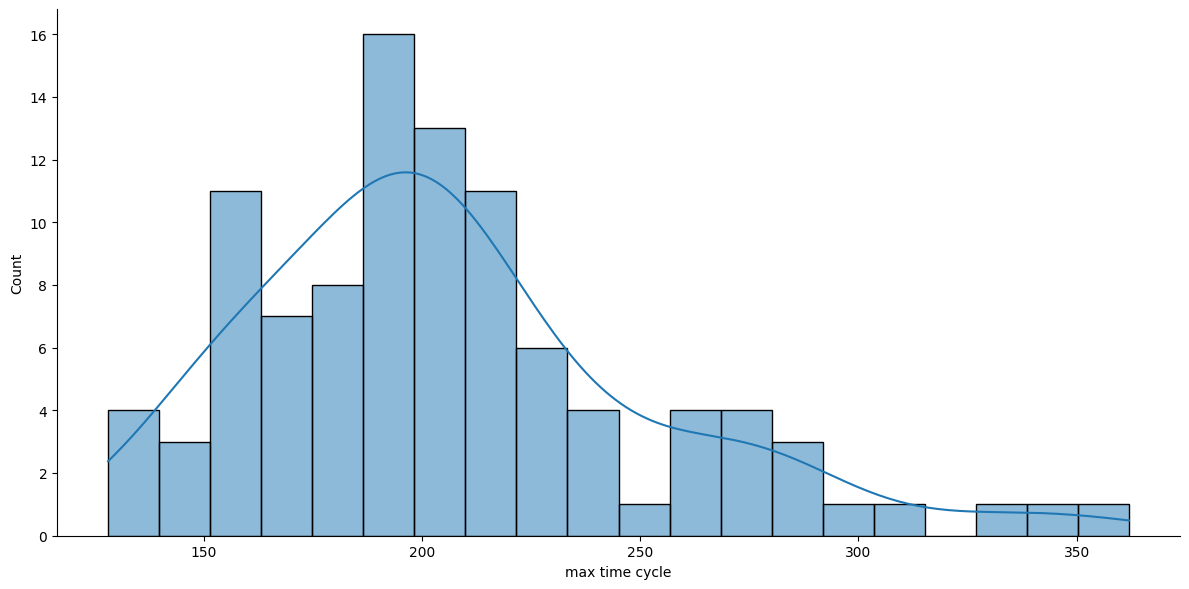

In [ ]:
#Distribution of maximum time cycles
sns.displot(max_time_cycles['time_cycles'],kde=True,bins=20,height=6,aspect=2)
plt.xlabel('max time cycle')

In [ ]:
def add_RUL_column(df):
    train_grouped_by_unit = df.groupby(by='unit_number')
    max_time_cycles = train_grouped_by_unit['time_cycles'].max()
    merged = df.merge(max_time_cycles.to_frame(name='max_time_cycle'), left_on='unit_number',right_index=True)
    merged["RUL"] = merged["max_time_cycle"] - merged['time_cycles']
    merged = merged.drop("max_time_cycle", axis=1)
    return merged

In [ ]:
train = add_RUL_column(train)


In [ ]:
train[['unit_number','RUL']]


,unit_number,RUL
0,1,191
1,1,190
2,1,189
3,1,188
4,1,187
...,...,...
20626,100,4
20627,100,3
20628,100,2
20629,100,1


In [ ]:
# For valid, add RUL from y_valid
valid_grouped = valid.groupby('unit_number')
valid_max_cycles = valid_grouped['time_cycles'].max().reset_index()
valid = valid.merge(valid_max_cycles, on='unit_number', suffixes=('', '_max'))
valid['RUL'] = valid['time_cycles_max'] - valid['time_cycles']
valid['RUL'] = np.minimum(valid['RUL'], 125)
valid = valid.drop('time_cycles_max', axis=1)
valid['RUL'] = valid['RUL'] + y_valid['RUL']  # Adjust with ground truth end RUL

In [ ]:
valid

,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,142.0
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,127.0
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,97.0
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,109.0
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,117.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974,NaN
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771,NaN
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051,NaN
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699,NaN


In [ ]:
# Select relevant sensors (drop constants)
constant_sensors = ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
selected_sensors = [s for s in sensor_names if s not in constant_sensors]
features = setting_names + selected_sensors

In [ ]:
# Normalize
scaler = MinMaxScaler()
train[features] = scaler.fit_transform(train[features])
valid[features] = scaler.transform(valid[features])

In [ ]:
train


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.459770,0.166667,0.0,518.67,0.183735,0.406802,0.309757,14.62,...,0.205882,0.199608,0.363986,0.03,0.333333,2388,100.0,0.713178,0.724662,191
1,1,2,0.609195,0.250000,0.0,518.67,0.283133,0.453019,0.352633,14.62,...,0.279412,0.162813,0.411312,0.03,0.333333,2388,100.0,0.666667,0.731014,190
2,1,3,0.252874,0.750000,0.0,518.67,0.343373,0.369523,0.370527,14.62,...,0.220588,0.171793,0.357445,0.03,0.166667,2388,100.0,0.627907,0.621375,189
3,1,4,0.540230,0.500000,0.0,518.67,0.343373,0.256159,0.331195,14.62,...,0.294118,0.174889,0.166603,0.03,0.333333,2388,100.0,0.573643,0.662386,188
4,1,5,0.390805,0.333333,0.0,518.67,0.349398,0.257467,0.404625,14.62,...,0.235294,0.174734,0.402078,0.03,0.416667,2388,100.0,0.589147,0.704502,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,0.477011,0.250000,0.0,518.67,0.686747,0.587312,0.782917,14.62,...,0.558824,0.194344,0.656791,0.03,0.750000,2388,100.0,0.271318,0.109500,4
20627,100,197,0.408046,0.083333,0.0,518.67,0.701807,0.729453,0.866475,14.62,...,0.500000,0.188668,0.727203,0.03,0.583333,2388,100.0,0.124031,0.366197,3
20628,100,198,0.522989,0.500000,0.0,518.67,0.665663,0.684979,0.775321,14.62,...,0.529412,0.212148,0.922278,0.03,0.833333,2388,100.0,0.232558,0.053991,2
20629,100,199,0.436782,0.750000,0.0,518.67,0.608434,0.746021,0.747468,14.62,...,0.514706,0.203065,0.823394,0.03,0.583333,2388,100.0,0.116279,0.234466,1


In [ ]:
# Windowing
def create_windows(df, window_size):
    X, y = [], []
    for name, group in df.groupby('unit_number'):
        if len(group) >= window_size:
            for i in range(len(group) - window_size + 1):
                X.append(group[features].iloc[i:i+window_size].values)
                y.append(group['RUL'].iloc[i+window_size-1])
    return np.array(X), np.array(y)


In [ ]:
window_size = 30  # Example
X_train, y_train = create_windows(train, window_size)
X_valid, y_valid = create_windows(valid, window_size)

In [ ]:
X_train

array([[[0.45977011, 0.16666667, 0.        , ..., 0.33333333,
         0.71317829, 0.7246617 ],
        [0.6091954 , 0.25      , 0.        , ..., 0.33333333,
         0.66666667, 0.73101353],
        [0.25287356, 0.75      , 0.        , ..., 0.16666667,
         0.62790698, 0.62137531],
        ...,
        [0.36206897, 0.91666667, 0.        , ..., 0.16666667,
         0.6744186 , 0.53838719],
        [0.56896552, 0.41666667, 0.        , ..., 0.41666667,
         0.6124031 , 0.64277824],
        [0.37356322, 0.5       , 0.        , ..., 0.16666667,
         0.70542636, 0.71361502]],

       [[0.6091954 , 0.25      , 0.        , ..., 0.33333333,
         0.66666667, 0.73101353],
        [0.25287356, 0.75      , 0.        , ..., 0.16666667,
         0.62790698, 0.62137531],
        [0.54022989, 0.5       , 0.        , ..., 0.33333333,
         0.57364341, 0.66238608],
        ...,
        [0.56896552, 0.41666667, 0.        , ..., 0.41666667,
         0.6124031 , 0.64277824],
        [0.3

In [ ]:
# Step 2: Creating Graph
# Temporal graph: Nodes as time steps in window, features as sensor values, edges consecutive + similarity
def create_temporal_graph(window_data, k=3, threshold=0.8):
    num_steps, num_sensors = window_data.shape
    node_features = torch.tensor(window_data, dtype=torch.float)  # (num_steps, num_sensors)

    # Temporal edges: Connect consecutive time steps
    temporal_edges = []
    for i in range(num_steps - 1):
        temporal_edges.append([i, i+1])
        temporal_edges.append([i+1, i])  # Undirected
    temporal_edges = torch.tensor(temporal_edges).t()

    # Similarity edges: kNN based on cosine similarity between time steps
    from sklearn.metrics.pairwise import cosine_similarity
    sim_matrix = cosine_similarity(window_data)
    sim_edges = []
    for i in range(num_steps):
        sim_scores = sim_matrix[i]
        top_k = np.argsort(-sim_scores)[1:k+1]  # Exclude self
        for j in top_k:
            if sim_scores[j] > threshold:
                sim_edges.append([i, j])
                sim_edges.append([j, i])
    sim_edges = torch.tensor(sim_edges).t()

    # Combine edges
    edge_index = torch.cat([temporal_edges, sim_edges], dim=1)

    return Data(x=node_features, edge_index=edge_index)

In [ ]:
# Dataset class
class GraphDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        graph = create_temporal_graph(self.X[idx])
        graph.y = torch.tensor([[self.y[idx]]], dtype=torch.float)  # Shape: [1, 1] instead of [1]
        return graph

In [ ]:
train_dataset = GraphDataset(X_train, y_train)
valid_dataset = GraphDataset(X_valid, y_valid)

In [ ]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
# Step 3: Define GAT Model
class GATModel(nn.Module):
    def __init__(self, in_features, hidden_dim=64, out_dim=1, num_heads=4):
        super(GATModel, self).__init__()
        self.conv1 = GATConv(in_features, hidden_dim, heads=num_heads)
        self.conv2 = GATConv(hidden_dim * num_heads, hidden_dim, heads=1)
        self.fc = nn.Linear(hidden_dim, out_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        batch = data.batch if hasattr(data, 'batch') else None
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index).relu()
        # Global mean pooling
        if batch is not None:
            from torch_geometric.nn import global_mean_pool
            x = global_mean_pool(x, batch)
        else:
            x = x.mean(dim=0)
        return self.fc(x)

In [ ]:
model = GATModel(in_features=len(features))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

In [ ]:
# Step 4: Training
num_epochs = 50
train_losses = []
valid_losses = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.num_graphs
    train_loss /= len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    valid_loss = 0
    with torch.no_grad():
        for batch in valid_loader:
            out = model(batch)
            loss = criterion(out, batch.y)
            valid_loss += loss.item() * batch.num_graphs
    valid_loss /= len(valid_dataset)
    valid_losses.append(valid_loss)

    print(f'Epoch {epoch+1}: Train Loss {train_loss:.4f}, Valid Loss {valid_loss:.4f}')

Epoch 1: Train Loss 5351.5395, Valid Loss nan
Epoch 2: Train Loss 1659.4110, Valid Loss nan
Epoch 3: Train Loss 1539.4513, Valid Loss nan
Epoch 4: Train Loss 1498.2804, Valid Loss nan
Epoch 5: Train Loss 1473.0907, Valid Loss nan
Epoch 6: Train Loss 1457.0331, Valid Loss nan
Epoch 7: Train Loss 1445.2052, Valid Loss nan
Epoch 8: Train Loss 1428.9707, Valid Loss nan
Epoch 9: Train Loss 1422.2726, Valid Loss nan
Epoch 10: Train Loss 1406.3143, Valid Loss nan
Epoch 11: Train Loss 1400.9177, Valid Loss nan
Epoch 12: Train Loss 1386.5243, Valid Loss nan
Epoch 13: Train Loss 1375.7653, Valid Loss nan
Epoch 14: Train Loss 1360.6803, Valid Loss nan
Epoch 15: Train Loss 1345.3873, Valid Loss nan
Epoch 16: Train Loss 1335.3105, Valid Loss nan
Epoch 17: Train Loss 1322.8922, Valid Loss nan
Epoch 18: Train Loss 1309.8665, Valid Loss nan
Epoch 19: Train Loss 1294.5999, Valid Loss nan
Epoch 20: Train Loss 1284.1419, Valid Loss nan
Epoch 21: Train Loss 1271.8148, Valid Loss nan
Epoch 22: Train Loss 1

In [ ]:
# Step 5: Evaluation
model.eval()
y_pred = []
with torch.no_grad():
    for batch in valid_loader:
        out = model(batch)
        y_pred.extend(out.cpu().numpy())

y_pred = np.array(y_pred).flatten()
y_valid = np.array(y_valid)

In [ ]:
# Calculate Metrics
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
mae = mean_absolute_error(y_valid, y_pred)

In [ ]:
# Score function (CMAPSS-specific)
def compute_score(y_true, y_pred):
    score = 0
    for t, p in zip(y_true, y_pred):
        d = p - t
        if d < 0:
            score += np.exp(-d / 13) - 1
        else:
            score += np.exp(d / 10) - 1
    return score

score = compute_score(y_valid, y_pred)
print(f'RMSE: {rmse:.4f}, MAE: {mae:.4f}, Score: {score:.4f}')

In [ ]:
# Step 6: Visualization
# Loss Curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, num_epochs+1), valid_losses, label='Valid Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [ ]:
# Scatter Plot
plt.figure(figsize=(10, 5))
plt.scatter(y_valid, y_pred, alpha=0.3)
plt.plot([0, max(y_valid)], [0, max(y_valid)], 'r--')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Predicted vs True RUL')
plt.show()

In [ ]:
# Chart: Bar Comparison with Baselines
baselines = {
    'LSTM': {'RMSE': 16.14, 'MAE': 13.00, 'Score': 595.0},  # From Nature 2025
    'Deep LSTM': {'RMSE': 15.10, 'MAE': 12.00, 'Score': 550.0},  # Approximate
    'GAT (Ours)': {'RMSE': rmse, 'MAE': mae, 'Score': score}
}

chart_data = {
    'Model': baselines.keys(),
    'RMSE': [metrics['RMSE'] for metrics in baselines.values()],
    'MAE': [metrics['MAE'] for metrics in baselines.values()],
    'Score': [metrics['Score'] for metrics in baselines.values()]
}
chart_df = pd.DataFrame(chart_data)

In [ ]:
# Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
bar_width = 0.25
index = np.arange(len(chart_data['Model']))
ax.bar(index, chart_df['RMSE'], bar_width, label='RMSE')
ax.bar(index + bar_width, chart_df['MAE'], bar_width, label='MAE')
ax.bar(index + 2 * bar_width, chart_df['Score'] / max(chart_df['Score']) * max(chart_df['RMSE']), bar_width, label='Score (Scaled)')
ax.set_xlabel('Model')
ax.set_ylabel('Metric Value')
ax.set_title('Performance Comparison with Baselines')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(chart_data['Model'])
ax.legend()
plt.tight_layout()
plt.show()